In [1]:
%pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 31.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [shap]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

variables = pd.read_parquet("data/clean/variables_modelo.parquet")
X = variables.drop(columns=["id_cliente", "sexo", "impago_mes_siguiente"])
y = variables["impago_mes_siguiente"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

modelo_lgb = joblib.load("data/clean/modelo_lightgbm.joblib")

explicador = shap.TreeExplainer(modelo_lgb)
sv = explicador(X_test)
print("Explicaciones calculadas:", sv.values.shape)

/opt/miniconda3/envs/credito/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Explicaciones calculadas: (8973, 18)


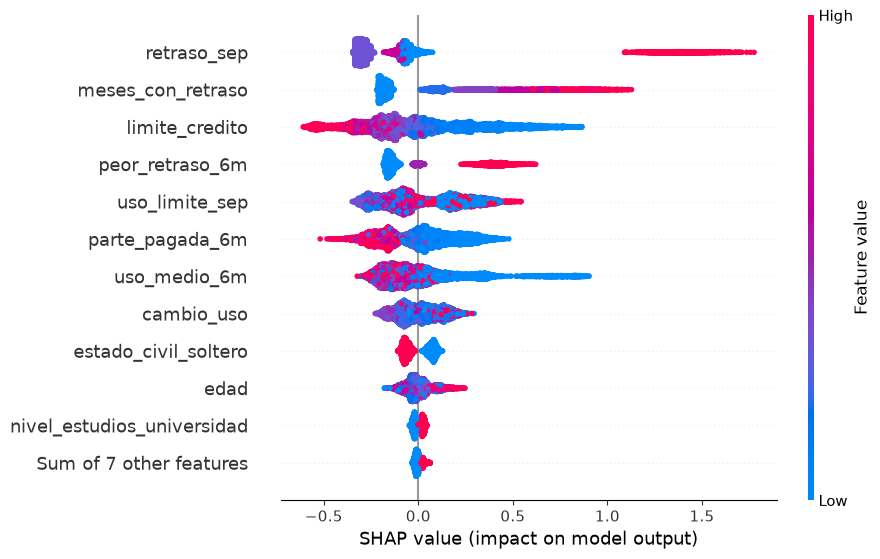

In [3]:
shap.plots.beeswarm(sv, max_display=12)

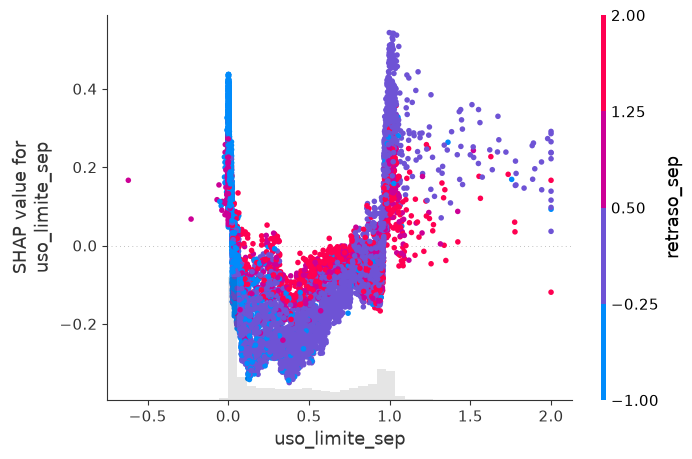

In [4]:
shap.plots.scatter(sv[:, "uso_limite_sep"], color=sv[:, "retraso_sep"])

PD de este cliente: 19.6% · ¿No pagó de verdad?: 0.0


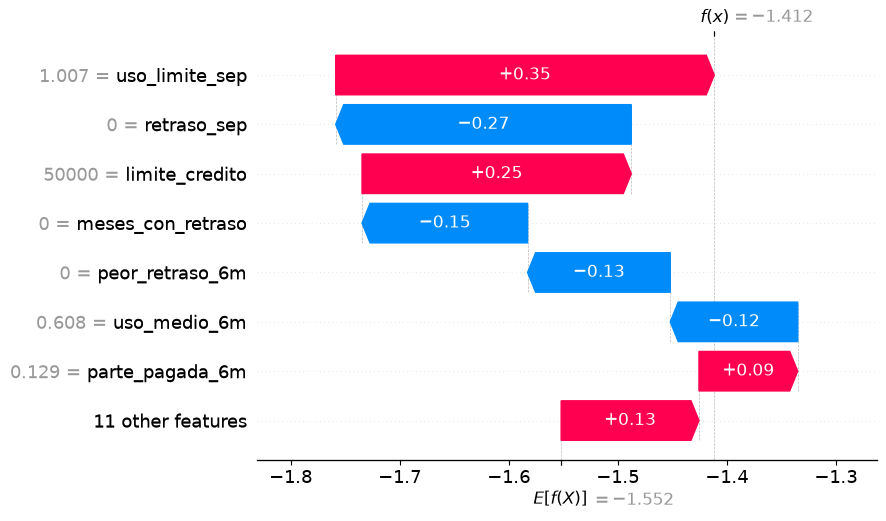

In [5]:
i = 0
pd_cliente = modelo_lgb.predict_proba(X_test.iloc[[i]])[0, 1]
print(f"PD de este cliente: {pd_cliente:.1%} · ¿No pagó de verdad?: {y_test.iloc[i]}")
shap.plots.waterfall(sv[i], max_display=8)

In [6]:
nombres = {
    "retraso_sep": "retraso en el pago de septiembre",
    "meses_con_retraso": "meses con retraso en el último medio año",
    "peor_retraso_6m": "retrasos importantes en los últimos meses",
    "uso_limite_sep": "uso alto del límite de la tarjeta",
    "uso_medio_6m": "uso alto del límite en los últimos meses",
    "parte_pagada_6m": "pagos bajos respecto a lo facturado",
    "limite_credito": "límite de crédito bajo",
    "cambio_uso": "deuda en aumento",
    "edad": "edad",
}

def motivos(i, n=3):
    aportes = pd.Series(sv.values[i], index=X.columns).sort_values(ascending=False)
    suben = aportes[aportes > 0].head(n)
    return [nombres.get(v, v) for v in suben.index]

for i in range(3):
    pd_i = modelo_lgb.predict_proba(X_test.iloc[[i]])[0, 1]
    print(f"Cliente {i}: PD {pd_i:.0%} → motivos: {', '.join(motivos(i))}")

Cliente 0: PD 20% → motivos: uso alto del límite de la tarjeta, límite de crédito bajo, pagos bajos respecto a lo facturado
Cliente 1: PD 62% → motivos: retraso en el pago de septiembre, retrasos importantes en los últimos meses, pagos bajos respecto a lo facturado
Cliente 2: PD 13% → motivos: límite de crédito bajo, pagos bajos respecto a lo facturado, deuda en aumento
